# ERCOT Hourly Dispatch — Cost vs. Emissions Pareto Frontier (no storage)

**Question:** how much does it cost to cut CO₂ emissions when dispatching the existing ERCOT fleet during **August 4–10, 2025**?

This extends `model_no_storage_no_emission.ipynb` by pricing emissions:

$$\min \; C(x) + \beta\, E(x)$$

where $C$ is generation + distance cost (\$) and $E$ is emissions (t CO₂eq). Solving for a range of carbon prices $\beta$ traces the **Pareto frontier**: every point is a dispatch where emissions cannot be reduced without raising cost.

**Still simplified:** no battery storage, no zone-to-zone transfers or line limits.

**Approach**
1. Load and check the same inputs as the baseline, plus emission factors in gCO₂eq/kWh.
2. Work out analytically which β values can change the dispatch (so we sample β where it matters).
3. Build the LP once, then re-solve with each β (only the objective changes, so Gurobi warm-starts).
4. Check every solution, then plot the frontier, emissions vs. β, and the generation mix vs. β.
5. Cross-check the frontier with the MultiObjectiveAlgorithms.jl package.

In [1]:
using CSV, DataFrames, JuMP, Gurobi, Plots, Printf, Statistics, TOML

commas(x; d = 0) = (s = @sprintf("%.*f", d, x); m = match(r"^(-?)(\d+)(\.\d+)?$", s);
                    m[1] * replace(m[2], r"(?<=\d)(?=(\d{3})+$)" => ",") * something(m[3], ""))
table(df) = display(HTML(sprint(io -> show(io, MIME("text/html"), df; eltypes = false, summary = false,
                                            show_row_number = false))))
SHORT = Dict("Natural Gas - Combined Cycle" => "Gas CC", "Natural Gas - Non-Combined Cycle" => "Gas non-CC")
short(s) = get(SHORT, s, s)

short (generic function with 1 method)

## 1. Inputs and checks

Same files as the baseline notebook. **New:** `emission_costs.csv` is in **gCO₂eq/kWh**, which equals **kg CO₂eq/MWh**. Dividing by 1,000 gives **t CO₂eq/MWh**, so β is in **\$/t CO₂eq**.

In [2]:
REPO = normpath(joinpath(@__DIR__, ".."))
DATA = first(filter(isdir, [joinpath(REPO, "Data Processing", d, "cleaned_data") for d in ("data", "Data")]))
OUT  = joinpath(@__DIR__, "output", "model_no_storage_emission_pareto"); mkpath(OUT)

ZONES = ["COAST", "EAST", "FWEST", "NORTH", "NCENT", "SOUTH", "SCENT", "WEST"]
Δt    = 1.0
α     = Float64(TOML.parsefile(joinpath(REPO, "config.toml"))["transmission"]["alpha"])   # $/MWh per km

readcsv(f; kw...) = CSV.read(joinpath(DATA, f), DataFrame; stripwhitespace = true, kw...)
gens  = readcsv("generators_2025-08-04.csv"; types = Dict(:id => String))
load  = readcsv("native_load_2025_cleaned.csv"; types = Dict(Symbol("Hour Ending") => String))
cf    = readcsv("renewable_capacity_factors.csv"; types = Dict(Symbol("Hour Ending") => String))
fuel  = readcsv("Fuel_costs.csv")
emis  = readcsv("emission_costs.csv")
dist  = readcsv("distance_generator_zone.csv"; types = Dict(:generator_id => String))
rename!(fuel, strip.(replace.(names(fuel), '\ufeff' => "")))

hours = String.(load[!, "Hour Ending"])
checks = [
    (nrow(gens) == 679 && allunique(gens.id),                         "679 generators, unique ids"),
    (length(hours) == 168 && allunique(hours),                        "168 unique hours"),
    (String.(cf[!, "Hour Ending"]) == hours,                          "capacity-factor hours = load hours, same order (incl. 24:00)"),
    (maximum(abs.(sum(Matrix(load[!, ZONES]); dims = 2) .- load.ERCOT)) <= 0.05, "zones add up to the ERCOT total (±0.05 MW)"),
    (all(x -> 0 <= x <= 1, [cf.solar_capacity_factor; cf.wind_capacity_factor]), "capacity factors within [0, 1]"),
    (Set(dist.generator_id) == Set(gens.id) && allunique(dist.generator_id),     "distance ids = generator ids"),
    (Set(gens[!, "Energy Source"]) ⊆ Set(fuel.energy_source),          "every technology has a fuel cost"),
    (Set(gens[!, "Energy Source"]) ⊆ Set(emis.energy_source),          "every technology has an emission factor"),
    (all(>=(0), emis.value),                                          "emission factors ≥ 0"),
]
println("Data folder: ", relpath(DATA, REPO), "   |   α = $α \$/MWh per km")
table(DataFrame(check = last.(checks), result = [ok ? "✔ pass" : "✘ FAIL" for ok in first.(checks)]))
all(first.(checks)) || error("A data check failed — see the table above.")

Data folder: Data Processing/data/cleaned_data

   |   α = 0.001223 $/MWh per km


check,result
"679 generators, unique ids",✔ pass
168 unique hours,✔ pass
"capacity-factor hours = load hours, same order (incl. 24:00)",✔ pass
zones add up to the ERCOT total (±0.05 MW),✔ pass
"capacity factors within [0, 1]",✔ pass
distance ids = generator ids,✔ pass
every technology has a fuel cost,✔ pass
every technology has an emission factor,✔ pass
emission factors ≥ 0,✔ pass


true

## 2. Parameters

In [3]:
ids  = gens.id
tech = String.(gens[!, "Energy Source"])
I, J, T = length(ids), length(ZONES), length(hours)

cost_of = Dict(r.energy_source => Float64(r.marginal_cost_usd_per_mwh) for r in eachrow(fuel))
ef_g    = Dict(r.energy_source => Float64(r.value) for r in eachrow(emis))     # gCO₂eq/kWh = kg/MWh
c = [cost_of[s] for s in tech]                                                 # $/MWh
e = [ef_g[s] / 1000 for s in tech]                                             # t CO₂eq / MWh

row = Dict(g => k for (k, g) in enumerate(dist.generator_id))
d = [Float64(dist[row[g], z]) for g in ids, z in ZONES]                        # km
D = Matrix{Float64}(load[!, ZONES])' .* Δt                                     # J × T, MWh

nameplate, summer = Float64.(gens[!, "Nameplate Capacity (MW)"]), Float64.(gens[!, "Summer Capacity (MW)"])
cap = zeros(I, T)
for i in 1:I, t in 1:T
    cap[i, t] = tech[i] == "Solar" ? nameplate[i] * cf.solar_capacity_factor[t] * Δt :
                tech[i] == "Wind"  ? nameplate[i] * cf.wind_capacity_factor[t]  * Δt :
                                     summer[i] * Δt
end
all(vec(sum(cap; dims = 1)) .>= vec(sum(D; dims = 1))) || error("Not enough capacity in some hour.")

TECHS = sort(unique(tech); by = s -> (cost_of[s], s))                          # merit order
table(DataFrame("Technology" => short.(TECHS),
                "Cost (\$/MWh)" => [@sprintf("%.2f", cost_of[s]) for s in TECHS],
                "Emissions (gCO₂eq/kWh)" => [commas(ef_g[s]) for s in TECHS],
                "Emissions (t/MWh)" => [@sprintf("%.3f", ef_g[s] / 1000) for s in TECHS],
                "Avg hourly capacity (GW)" => [@sprintf("%.1f", sum(cap[tech .== s, :]) / T / 1000) for s in TECHS]))

Technology,Cost ($/MWh),Emissions (gCO₂eq/kWh),Emissions (t/MWh),Avg hourly capacity (GW)
Solar,0.00,0,0.000,8.6
Wind,0.00,0,0.000,14.7
Nuclear,12.76,0,0.000,5.0
Hydro,15.14,0,0.000,0.5
Gas CC,22.83,392,0.392,38.7
Coal,31.36,"1,062",1.062,12.7
Gas non-CC,33.88,392,0.392,20.2


## 3. Which carbon prices can change the dispatch?

With a carbon price β, each technology's effective cost becomes $c_i + \beta\, e_i$. The dispatch only changes when β reorders two technologies, so it switches from A to B when

$$\beta^\* = \frac{c_B - c_A}{e_A - e_B} \qquad (\text{B costs more but emits less}).$$

- Solar, wind, nuclear and hydro emit nothing, are the cheapest, and already run at 100% — a carbon price cannot add more of them.
- Gas CC is both cheaper **and** cleaner than coal, so no β changes that order.
- The only real trade-off is **coal → Gas non-CC** (same emissions as Gas CC, but more expensive than coal).

In [4]:
pairs = [(a, b) for a in TECHS for b in TECHS if cost_of[b] > cost_of[a] && ef_g[b] < ef_g[a]]
table(DataFrame("Switch from (dirtier, cheaper)" => [short(a) for (a, _) in pairs],
                "to (cleaner, pricier)" => [short(b) for (_, b) in pairs],
                "Break-even β (\$/t)" => [@sprintf("%.2f", (cost_of[b] - cost_of[a]) / (ef_g[a] / 1000 - ef_g[b] / 1000)) for (a, b) in pairs]))

"Switch from (dirtier, cheaper)","to (cleaner, pricier)",Break-even β ($/t)
Coal,Gas non-CC,3.77


Distance cost ($\alpha d_{ij}$) shifts the break-even slightly from plant to plant (a coal plant far from demand switches a bit earlier), so the coal → Gas non-CC switch is spread over a narrow band around \$3.77/t rather than one exact value. A first sweep in \$0.25 steps showed the whole transition happens between **\$3.25 and \$4.00/t**.

**β values chosen (31 solves, ~10 s total):**
- a few points below the transition (0, 1, 2, 2.5, 3) to confirm nothing changes,
- **\$0.05/t steps from \$3.00 to \$4.10/t** to trace the transition itself,
- a few higher prices (5, 10, 25, 50, 100, **190**) to show the frontier is flat beyond it — \$190/t is the U.S. EPA (2023) social cost of carbon.

In [5]:
βs = vcat([0, 1, 2, 2.5], 3.0:0.05:4.1, [5, 10, 25, 50, 100, 190]) .|> Float64
βs = unique(round.(βs; digits = 2))
println(length(βs), " carbon prices from \$", βs[1], " to \$", βs[end], " per t CO₂eq")

33 carbon prices from $

0.0 to $190.0 per t CO₂eq


## 4. Model

Same LP as the baseline; only the objective has the emission term added:

$$
\min \; \underbrace{\sum_{i,j,t} \big(c_i + \alpha\, d_{ij}\big)\, x_{ijt}}_{C:\ \text{cost (\$)}} \;+\; \beta\, \underbrace{\sum_{i,j,t} e_i\, x_{ijt}}_{E:\ \text{emissions (t)}}
\quad \text{s.t.} \quad \sum_i x_{ijt} \ge D_{jt}, \quad \sum_j x_{ijt} \le \bar g_{it}, \quad x \ge 0.
$$

The constraints do not depend on β, so the model is built once and only the objective is replaced for each β.

In [6]:
model = Model(Gurobi.Optimizer)
set_silent(model)

@variable(model, x[1:I, 1:J, 1:T] >= 0)
@constraint(model, demand[j in 1:J, t in 1:T],   sum(x[i, j, t] for i in 1:I) >= D[j, t])
@constraint(model, capacity[i in 1:I, t in 1:T], sum(x[i, j, t] for j in 1:J) <= cap[i, t])

@expression(model, C_gen,  sum(c[i] * x[i, j, t] for i in 1:I, j in 1:J, t in 1:T))           # $
@expression(model, C_dist, sum(α * d[i, j] * x[i, j, t] for i in 1:I, j in 1:J, t in 1:T))     # $
@expression(model, E,      sum(e[i] * x[i, j, t] for i in 1:I, j in 1:J, t in 1:T))           # t CO₂eq

println("\nVariables: ", commas(num_variables(model)),
        "   Constraints: ", commas(num_constraints(model; count_variable_in_set_constraints = false)))

Set parameter Username
Set parameter LicenseID to value 2857569
Academic license - for non-commercial use only - expires 2027-08-26

Variables: 912,576

   Constraints: 115,416


### Solve for every β

In [7]:
results = DataFrame(beta = Float64[], status = String[], solve_s = Float64[], gen_cost = Float64[],
                    dist_cost = Float64[], emissions_t = Float64[], objective = Float64[],
                    max_shortfall = Float64[], max_cap_viol = Float64[])
mix = Dict{Float64,Dict{String,Float64}}()

for β in βs
    @objective(model, Min, C_gen + C_dist + β * E)
    optimize!(model)
    ok = termination_status(model) == MOI.OPTIMAL && primal_status(model) == MOI.FEASIBLE_POINT
    ok || error("β = $β: ", termination_status(model))
    X   = value.(x)
    gen = dropdims(sum(X; dims = 2); dims = 2)
    sup = dropdims(sum(X; dims = 1); dims = 1)
    push!(results, (β, string(termination_status(model)), solve_time(model), value(C_gen), value(C_dist),
                    value(E), objective_value(model), max(0, maximum(D .- sup)), max(0, maximum(gen .- cap))))
    mix[β] = Dict(s => sum(gen[tech .== s, :]) for s in TECHS)
end
results.cost = results.gen_cost .+ results.dist_cost                  # actual system cost, excl. carbon charge
println("Solved ", nrow(results), " LPs in ", @sprintf("%.0f", sum(results.solve_s)), " s total.")

Solved 33

 LPs in 15 s total.


## 5. Check every solution

In [8]:
base = results[1, :]
min_E_bound = let total = 0.0                                          # emissions merit order: cleanest first
    order = sortperm(e)
    for t in 1:T
        need = sum(D[:, t])
        for i in order
            q = min(need, cap[i, t]); total += e[i] * q; need -= q
            need <= 1e-9 && break
        end
    end
    total
end
table(DataFrame("Check" => ["All solves optimal", "Largest demand shortfall (any β)", "Largest capacity violation (any β)",
                            "Objective = cost + β × emissions (max diff)", "β = 0 cost matches baseline notebook (\$167.10 M)",
                            "Emissions never increase as β rises", "Lowest emissions vs. physical minimum"],
                "Value" => [string(all(results.status .== "OPTIMAL")),
                            @sprintf("%.1e MWh", maximum(results.max_shortfall)),
                            @sprintf("%.1e MWh", maximum(results.max_cap_viol)),
                            @sprintf("%.1e \$", maximum(abs.(results.objective .- results.cost .- results.beta .* results.emissions_t))),
                            @sprintf("\$%.2f M", base.cost / 1e6),
                            string(all(diff(results.emissions_t) .<= 1e-3)),
                            @sprintf("%.4f vs %.4f Mt", minimum(results.emissions_t) / 1e6, min_E_bound / 1e6)]))

Check,Value
All solves optimal,true
Largest demand shortfall (any β),4.0e-11 MWh
Largest capacity violation (any β),5.7e-14 MWh
Objective = cost + β × emissions (max diff),1.6e-05 $
β = 0 cost matches baseline notebook ($167.10 M),$167.10 M
Emissions never increase as β rises,true
Lowest emissions vs. physical minimum,2.5553 vs 2.5553 Mt


## 6. Results
### 6.1 Frontier table
**Cost** is the real system cost (generation + distance) — the carbon charge β·E is a pricing device, not money spent. Compared with β = 0. Only the β values that change the dispatch are shown (plus the highest β); the full list is in `pareto_results.csv`.

In [9]:
pareto = unique(results, [:emissions_t])                              # drop β values that give the same dispatch
pareto.Δcost   = pareto.cost .- base.cost
pareto.Δemis   = base.emissions_t .- pareto.emissions_t
keep = [k == 1 || k == nrow(results) || abs(results.emissions_t[k] - results.emissions_t[k-1]) > 1 for k in 1:nrow(results)]
shown = results[keep, :]
table(DataFrame("β (\$/t)" => [@sprintf("%.2f", b) for b in shown.beta],
                "Cost (\$ M)" => [@sprintf("%.3f", v / 1e6) for v in shown.cost],
                "Emissions (kt CO₂eq)" => [commas(v / 1e3; d = 1) for v in shown.emissions_t],
                "Cut vs β=0" => [@sprintf("%.1f%%", 100 * (base.emissions_t - v) / base.emissions_t) for v in shown.emissions_t],
                "Extra cost vs β=0 (\$ M)" => [@sprintf("%.3f", (v - base.cost) / 1e6) for v in shown.cost],
                "Avg abatement cost (\$/t)" => [r.emissions_t < base.emissions_t - 1 ? @sprintf("%.2f", (r.cost - base.cost) / (base.emissions_t - r.emissions_t)) : "—"
                                                  for r in eachrow(shown)],
                "Coal (GWh)" => [commas(mix[b]["Coal"] / 1e3; d = 1) for b in shown.beta],
                "Gas non-CC (GWh)" => [commas(mix[b]["Natural Gas - Non-Combined Cycle"] / 1e3; d = 1) for b in shown.beta]))

β ($/t),Cost ($ M),Emissions (kt CO₂eq),Cut vs β=0,Extra cost vs β=0 ($ M),Avg abatement cost ($/t),Coal (GWh),Gas non-CC (GWh)
0.00,167.103,"2,913.8",0.0%,0.000,—,535.2,16.5
3.15,167.103,"2,913.8",0.0%,0.000,3.12,535.2,16.5
3.20,167.104,"2,913.4",0.0%,0.001,3.17,534.5,17.2
3.30,167.106,"2,912.9",0.0%,0.003,3.23,533.7,17.9
3.35,167.107,"2,912.6",0.0%,0.004,3.25,533.3,18.3
3.40,167.130,"2,905.8",0.3%,0.027,3.37,523.1,28.5
3.45,167.181,"2,890.9",0.8%,0.078,3.41,500.9,50.7
3.50,167.242,"2,873.4",1.4%,0.139,3.44,474.8,76.9
3.55,167.327,"2,849.2",2.2%,0.224,3.47,438.7,113.0
3.60,167.484,"2,805.4",3.7%,0.381,3.51,373.3,178.4


### 6.2 Pareto frontier
Each dot is one β. Moving left (fewer emissions) costs more. The frontier is short because only coal → Gas non-CC can be traded.

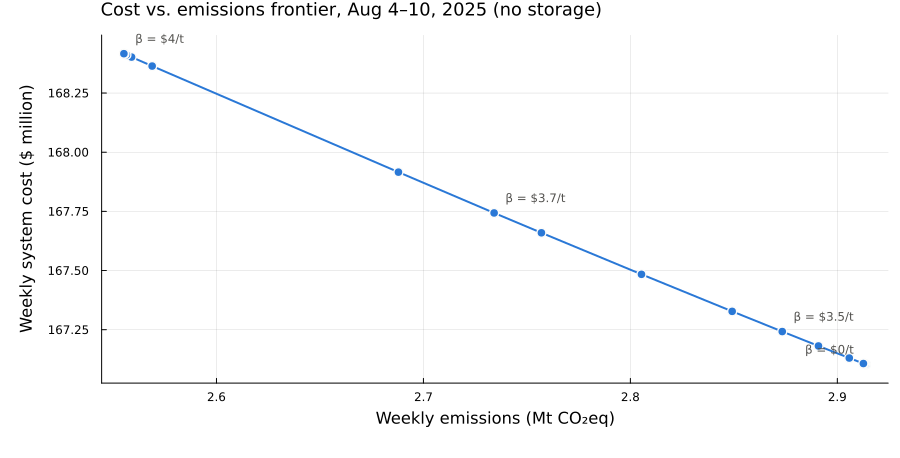

In [10]:
gr()
lbl_β = [0.0, 3.5, 3.7, 4.0]
p1 = plot(pareto.emissions_t ./ 1e6, pareto.cost ./ 1e6; seriestype = :path, color = "#2a78d6", linewidth = 2,
          marker = :circle, markersize = 5, markerstrokecolor = "#fcfcfb", markerstrokewidth = 1.5,
          legend = false, size = (900, 460), xflip = false,
          xlabel = "Weekly emissions (Mt CO₂eq)", ylabel = "Weekly system cost (\$ million)",
          title = "Cost vs. emissions frontier, Aug 4–10, 2025 (no storage)", titlelocation = :left, titlefontsize = 12,
          gridalpha = 0.15, left_margin = 5Plots.mm, bottom_margin = 5Plots.mm)
for r in eachrow(results)
    r.beta in lbl_β || continue
    lab = "β = \$" * (r.beta == round(r.beta) ? string(Int(r.beta)) : string(r.beta)) * "/t"
    # labels sit in the empty space above the line; β = 0 (far right) goes up-left
    dx = 0.006; dy = 0.035
    annotate!(p1, r.emissions_t / 1e6 + (r.beta == 0 ? -dx : dx), r.cost / 1e6 + dy,
              text(lab, 8, "#52514e", r.beta == 0 ? :right : :left, :bottom))
end
xr = extrema(results.emissions_t ./ 1e6); yr = extrema(results.cost ./ 1e6)
plot!(p1; xlims = (xr[1] - 0.03 * (xr[2] - xr[1]), xr[2] + 0.03 * (xr[2] - xr[1])),
          ylims = (yr[1] - 0.06 * (yr[2] - yr[1]), yr[2] + 0.06 * (yr[2] - yr[1])))
savefig(p1, joinpath(OUT, "pareto_frontier.png"))
p1

### 6.3 Emissions and cost as the carbon price rises
Log scale on β so both the narrow \$3.25–4 transition and the high prices are visible (β = 0 is plotted at \$0.1). The tick at \$3.77 is the analytical break-even.

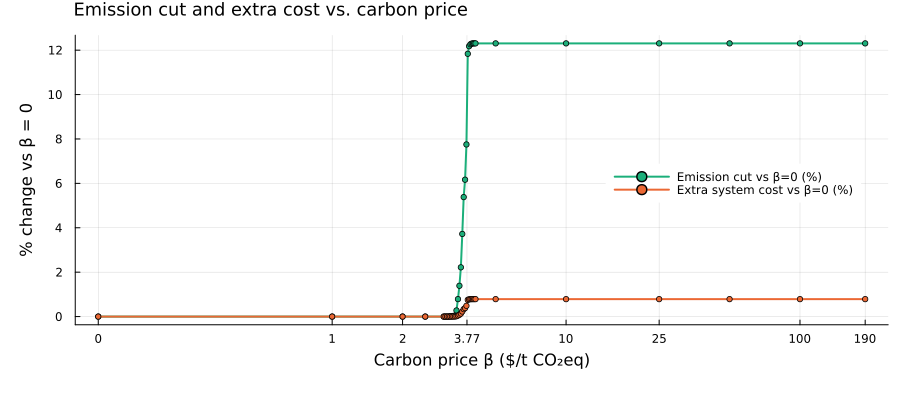

In [11]:
βplot = max.(results.beta, 0.1)
cut_pct = 100 .* (base.emissions_t .- results.emissions_t) ./ base.emissions_t
extra_pct = 100 .* (results.cost .- base.cost) ./ base.cost
p2 = plot(βplot, cut_pct; xscale = :log10, color = "#1baf7a", linewidth = 2, marker = :circle, markersize = 3,
          label = "Emission cut vs β=0 (%)", size = (900, 400),
          xticks = ([0.1, 1, 2, 3.77, 10, 25, 100, 190], ["0", "1", "2", "3.77", "10", "25", "100", "190"]),
          xlabel = "Carbon price β (\$/t CO₂eq)", ylabel = "% change vs β = 0",
          title = "Emission cut and extra cost vs. carbon price", titlelocation = :left, titlefontsize = 12,
          legend = :right, foreground_color_legend = nothing, gridalpha = 0.15, left_margin = 5Plots.mm, bottom_margin = 5Plots.mm)
plot!(p2, βplot, extra_pct; color = "#eb6834", linewidth = 2, marker = :circle, markersize = 3, label = "Extra system cost vs β=0 (%)")
savefig(p2, joinpath(OUT, "emissions_cost_vs_beta.png"))
p2

### 6.4 Generation mix vs. carbon price
Only coal and Gas non-CC move; everything else is unchanged.

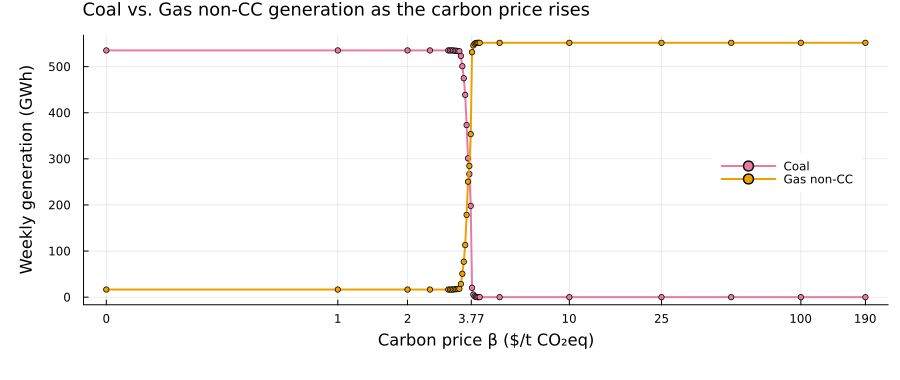

In [12]:
COLORS = Dict("Natural Gas - Combined Cycle" => "#2a78d6", "Wind" => "#eb6834", "Solar" => "#1baf7a",
              "Natural Gas - Non-Combined Cycle" => "#eda100", "Coal" => "#e87ba4", "Nuclear" => "#008300",
              "Hydro" => "#6250d6")
p3 = plot(size = (900, 380), xscale = :log10, xticks = ([0.1, 1, 2, 3.77, 10, 25, 100, 190], ["0", "1", "2", "3.77", "10", "25", "100", "190"]),
          xlabel = "Carbon price β (\$/t CO₂eq)", ylabel = "Weekly generation (GWh)",
          title = "Coal vs. Gas non-CC generation as the carbon price rises", titlelocation = :left, titlefontsize = 12,
          legend = :right, foreground_color_legend = nothing, gridalpha = 0.15, left_margin = 5Plots.mm, bottom_margin = 5Plots.mm)
for s in ("Coal", "Natural Gas - Non-Combined Cycle")
    plot!(p3, βplot, [mix[b][s] / 1e3 for b in results.beta]; color = COLORS[s], linewidth = 2, marker = :circle,
          markersize = 3, label = short(s))
end
savefig(p3, joinpath(OUT, "mix_vs_beta.png"))
p3

In [13]:
# Full mix at three representative prices (GWh)
show_β = [0.0, 4.0, 190.0]
table(DataFrame(vcat(["Technology" => short.(TECHS)],
                     ["β = \$$(Int(b))/t" => [commas(mix[b][s] / 1e3; d = 1) for s in TECHS] for b in show_β])))

Technology,β = $0/t,β = $4/t,β = $190/t
Solar,"1,444.1","1,444.1","1,444.1"
Wind,"2,462.0","2,462.0","2,462.0"
Nuclear,836.6,836.6,836.6
Hydro,88.9,88.9,88.9
Gas CC,"5,966.9","5,966.9","5,966.9"
Coal,535.2,0.0,0.0
Gas non-CC,16.5,551.7,551.7


### 6.5 Takeaways
The markdown below is filled from the results above.

In [14]:
lo = results[argmin(results.emissions_t), :]
first_full = results[findfirst(results.emissions_t .<= lo.emissions_t + 1), :]
first_move = results[findfirst(results.emissions_t .< base.emissions_t - 1), :]
println("• At β = 0 (cost only): cost \$", @sprintf("%.2f", base.cost / 1e6), " M, emissions ", @sprintf("%.3f", base.emissions_t / 1e6), " Mt CO₂eq.")
println("• Coal starts being displaced at β ≈ \$", first_move.beta, "/t and is fully replaced by Gas non-CC by β ≈ \$", first_full.beta, "/t.")
println("• Lowest achievable emissions: ", @sprintf("%.3f", lo.emissions_t / 1e6), " Mt (", @sprintf("%.1f", 100 * (base.emissions_t - lo.emissions_t) / base.emissions_t),
        "% cut) for \$", @sprintf("%.2f", (lo.cost - base.cost) / 1e6), " M extra (", @sprintf("%+.2f", 100 * (lo.cost - base.cost) / base.cost), "%).")
println("• Average abatement cost of that cut: \$", @sprintf("%.2f", (lo.cost - base.cost) / (base.emissions_t - lo.emissions_t)), "/t CO₂eq.")
println("• Above β ≈ \$", first_full.beta, "/t nothing changes: without storage or new clean capacity there is nothing left to switch.")

• At β = 0 (cost only): cost $167.10

 M, emissions 2.914 Mt CO₂eq.
• Coal starts being displaced at β ≈ $3.15/t and is fully replaced by Gas non-CC by β ≈ $4.0/t.
• Lowest achievable emissions: 2.555 Mt (12.3% cut) for $1.31 M extra (+0.79%).
• Average abatement cost of that cut: $3.66/t CO₂eq.
• Above β ≈ $4.0/t nothing changes: without storage or new clean capacity there is nothing left to switch.


## 6.6 Cross-check with a Pareto package: MultiObjectiveAlgorithms.jl

[MultiObjectiveAlgorithms.jl](https://github.com/jump-dev/MultiObjectiveAlgorithms.jl) (MOA) computes Pareto frontiers directly from a JuMP model with a **vector objective** `[cost, emissions]` — no β needed. It is used here to check the β sweep independently.

**Which MOA algorithm?**
- `MOA.Dichotomy()` finds every corner of the (piecewise-linear) LP frontier exactly. Tested on shorter windows, the frontier has **9 corners for 6 hours but 755 for 24 hours** — every hour has its own coal → Gas non-CC switch points, slightly different per plant and zone because of distance cost, and the weekly frontier combines them all. For the full week that means thousands of corners and hours of solving, for points that are visually indistinguishable.
- `MOA.EpsilonConstraint()` instead returns a fixed number of exact frontier points, evenly spaced, by minimising one objective with the other capped. **Used here, with 25 points.**

**Notes**
- MOA needs the solver wrapped: `Model(() -> MOA.Optimizer(Gurobi.Optimizer))`.
- Objectives are scaled to **\$ million** and **Mt**: with raw \$ and t (≈ 10⁸ vs 10⁶) the ε-constraint step became numerically infeasible.
- It is slow (~40 min for 25 points, vs ~12 s for the whole β sweep) because each point changes a constraint, so Gurobi cannot warm-start the way it does when only the objective changes. The result is therefore **cached** in `moa_epsilon_frontier.csv`: the cell below loads it if present and only re-solves when `RUN_MOA = true` or the file is missing.

In [15]:
import MultiObjectiveAlgorithms as MOA

RUN_MOA   = false                                    # set true to force a fresh (~40 min) MOA run
MOA_CACHE = joinpath(OUT, "moa_epsilon_frontier.csv")

if RUN_MOA || !isfile(MOA_CACHE)
    t0 = time()
    moa = Model(() -> MOA.Optimizer(Gurobi.Optimizer))
    set_silent(moa)
    set_attribute(moa, MOA.Algorithm(), MOA.EpsilonConstraint())
    set_attribute(moa, MOA.SolutionLimit(), 25)
    @variable(moa, y[1:I, 1:J, 1:T] >= 0)
    @constraint(moa, [j in 1:J, t in 1:T], sum(y[i, j, t] for i in 1:I) >= D[j, t])
    @constraint(moa, [i in 1:I, t in 1:T], sum(y[i, j, t] for j in 1:J) <= cap[i, t])
    @expression(moa, C_moa, sum((c[i] + α * d[i, j]) * y[i, j, t] for i in 1:I, j in 1:J, t in 1:T))
    @expression(moa, E_moa, sum(e[i] * y[i, j, t] for i in 1:I, j in 1:J, t in 1:T))
    @objective(moa, Min, [C_moa / 1e6, E_moa / 1e6])            # [$ million, Mt CO₂eq]
    optimize!(moa)
    println("MOA status: ", termination_status(moa), " | points: ", result_count(moa),
            " | subproblems: ", get_attribute(moa, MOA.SubproblemCount()), " | ", round(Int, time() - t0), " s")
    moa_pts = DataFrame(cost_musd = [objective_value(moa; result = k)[1] for k in 1:result_count(moa)],
                        emissions_mt = [objective_value(moa; result = k)[2] for k in 1:result_count(moa)])
    sort!(moa_pts, :emissions_mt)
    CSV.write(MOA_CACHE, moa_pts)
else
    moa_pts = CSV.read(MOA_CACHE, DataFrame)
    println("Loaded ", nrow(moa_pts), " MOA frontier points from ", relpath(MOA_CACHE, REPO),
            "  (set RUN_MOA = true to re-solve)")
end

Set parameter Username
Set parameter LicenseID to value 2857569
Academic license - for non-commercial use only - expires 2027-08-26
MOA status: OPTIMAL

 | points: 25 | subproblems: 50 | 3150 s


"/Users/christoffertan/Documents/MIT/15.C57 Optimization Methods/Optimizing-Generation-and-Storage-Dispatch-in-ERCOT/model/output/model_no_storage_emission_pareto/moa_epsilon_frontier.csv"

### Does the β sweep match MOA's frontier?
Both methods give exact optimal points on the same frontier, so:
- the two endpoints (cheapest, cleanest) should coincide;
- every MOA point should sit on the line through the β-sweep points (an LP frontier is piecewise linear between its corners), up to the small curvature between sweep samples.

Check,β sweep,MOA ε-constraint
Cleanest point: emissions (Mt),2.5553,2.5553
Cleanest point: cost ($ M),168.416,168.416
Cheapest point: emissions (Mt),2.9138,2.9138
Cheapest point: cost ($ M),167.103,167.103
MOA points vs. β-sweep line: largest gap,—,$0.3 k (0.0002% of cost)


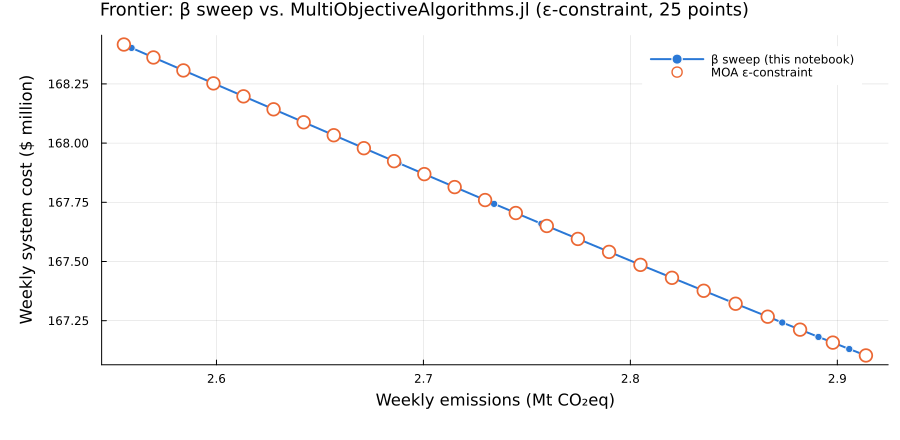

In [16]:
sw = sort(pareto, :emissions_t)
sw_E, sw_C = sw.emissions_t ./ 1e6, sw.cost ./ 1e6
interp(Eq) = (k = clamp(searchsortedlast(sw_E, Eq), 1, length(sw_E) - 1);
              sw_C[k] + (sw_C[k+1] - sw_C[k]) * (Eq - sw_E[k]) / (sw_E[k+1] - sw_E[k]))
gap_k = [1e3 * (interp(r.emissions_mt) - r.cost_musd) for r in eachrow(moa_pts)]     # $ thousand
table(DataFrame("Check" => ["Cleanest point: emissions (Mt)", "Cleanest point: cost (\$ M)",
                            "Cheapest point: emissions (Mt)", "Cheapest point: cost (\$ M)",
                            "MOA points vs. β-sweep line: largest gap"],
                "β sweep" => [@sprintf("%.4f", sw_E[1]), @sprintf("%.3f", sw_C[1]), @sprintf("%.4f", sw_E[end]), @sprintf("%.3f", sw_C[end]), "—"],
                "MOA ε-constraint" => [@sprintf("%.4f", moa_pts.emissions_mt[1]), @sprintf("%.3f", moa_pts.cost_musd[1]),
                                        @sprintf("%.4f", moa_pts.emissions_mt[end]), @sprintf("%.3f", moa_pts.cost_musd[end]),
                                        @sprintf("\$%.1f k  (%.4f%% of cost)", maximum(abs.(gap_k)), 100 * maximum(abs.(gap_k)) / 1e3 / sw_C[end])]))

p4 = plot(sw_E, sw_C; color = "#2a78d6", linewidth = 2, marker = :circle, markersize = 4, markerstrokecolor = "#fcfcfb",
          label = "β sweep (this notebook)", size = (900, 440),
          xlabel = "Weekly emissions (Mt CO₂eq)", ylabel = "Weekly system cost (\$ million)",
          title = "Frontier: β sweep vs. MultiObjectiveAlgorithms.jl (ε-constraint, 25 points)", titlelocation = :left, titlefontsize = 12,
          legend = :topright, foreground_color_legend = nothing, gridalpha = 0.15, left_margin = 5Plots.mm, bottom_margin = 5Plots.mm)
scatter!(p4, moa_pts.emissions_mt, moa_pts.cost_musd; marker = :circle, markersize = 7, markercolor = :white,
         markerstrokecolor = "#eb6834", markerstrokewidth = 2, label = "MOA ε-constraint")
savefig(p4, joinpath(OUT, "pareto_sweep_vs_moa.png"))
p4

## 7. Save outputs

In [17]:
CSV.write(joinpath(OUT, "pareto_results.csv"),
          DataFrame(beta_usd_per_t = results.beta, system_cost_usd = results.cost, generation_cost_usd = results.gen_cost,
                    distance_cost_usd = results.dist_cost, emissions_t_co2eq = results.emissions_t,
                    carbon_charge_usd = results.beta .* results.emissions_t, objective_usd = results.objective,
                    coal_mwh = [mix[b]["Coal"] for b in results.beta],
                    gas_noncc_mwh = [mix[b]["Natural Gas - Non-Combined Cycle"] for b in results.beta]))
println("Saved to ", relpath(OUT, REPO), ":")
for f in readdir(OUT)
    @printf("  %-28s %6s KB\n", f, commas(filesize(joinpath(OUT, f)) / 1024))
end

Saved to model/output/model_no_storage_emission_pareto

:
  emissions_cost_vs_beta.png       35 KB
  mix_vs_beta.png                  39 KB


  moa_epsilon_frontier.csv          1 KB
  pareto_frontier.png              44 KB
  pareto_results.csv                5 KB
  pareto_sweep_vs_moa.png          53 KB
